# The Three-Line BRDF + Drift Model, Worked Through on Synthetic Data

This notebook walks through the whiteboard system of equations using synthetic data where we *know* the truth, so we can watch the regression recover it.

The three lines:

**Line 1 — radiometric response model** (instrument only):
$$R_{\lambda,x,t} = a_{\lambda,x} + b_{\lambda,x}\, t$$

**Line 2 — observation model** (surface geometry response x instrument state):
$$\rho_{\lambda,x,\theta,t} = \left[c_{\lambda,x} + d_{\lambda,x}\cos\theta\right] R_{\lambda,x,t}$$

**Line 3 — the expansion** (what you actually fit):
$$\rho_{\lambda,x,\theta,t} = \alpha + \beta t + \gamma \cos\theta + \eta \cos\theta\, t$$

where $\alpha = ca$, $\beta = cb$, $\gamma = da$, $\eta = db$.

Throughout, we work with **one channel at one site**, so all $\lambda, x$ subscripts drop. The real pipeline repeats this [n_sites x n_wavelengths] times.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
plt.rcParams['figure.dpi'] = 110

## 1. Define the truth

We choose the four underlying physical parameters. These are the numbers the fit will never see directly — it only sees noisy observations.

Values are loosely EMIT-like: baseline apparent reflectance around 0.5, drift of -0.2% units/yr in absolute terms, and a bracket that varies a few percent over the SZA range.

In [2]:
# Line 1: R = a + b*t  (instrument response, t in years since first acquisition)
a_true = 0.520     # response at t = 0
b_true = -0.002    # drift slope, reflectance units per year

# Bracket: c + d*cos(theta)  (surface directional response)
c_true = 0.85
d_true = 0.18

print(f"True fractional drift rate  b/a = {100*b_true/a_true:+.3f} %/yr")
print(f"True BRDF sensitivity       d/c = {d_true/c_true:.4f}")

True fractional drift rate  b/a = -0.385 %/yr
True BRDF sensitivity       d/c = 0.2118


Note what we can already say: the *reportable* physics is in the ratios. `b/a` is the fractional drift rate (the paper's headline number), `d/c` is the site's fractional BRDF sensitivity. The raw four values are scaffolding.

Let's look at each factor in isolation — something only possible with synthetic data, since a real acquisition always delivers them multiplied together.

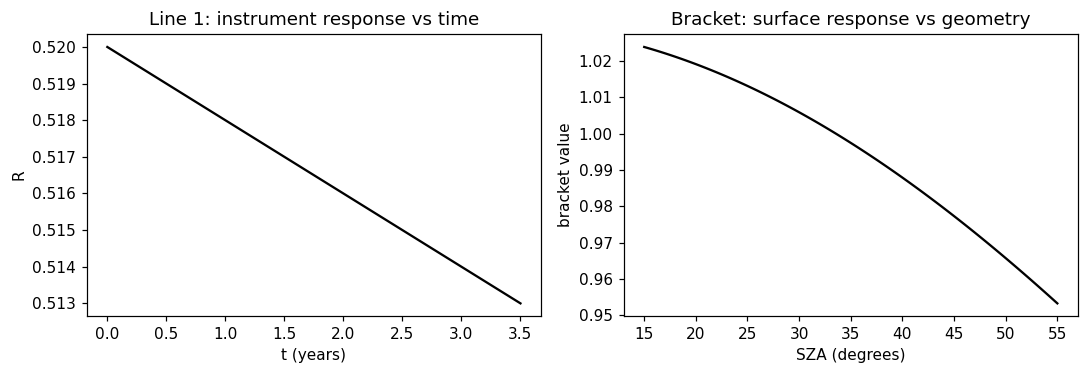

In [3]:
t_grid = np.linspace(0, 3.5, 100)
sza_grid = np.linspace(15, 55, 100)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].plot(t_grid, a_true + b_true * t_grid, 'k-')
axes[0].set_xlabel('t (years)'); axes[0].set_ylabel('R')
axes[0].set_title('Line 1: instrument response vs time')

axes[1].plot(sza_grid, c_true + d_true * np.cos(np.radians(sza_grid)), 'k-')
axes[1].set_xlabel('SZA (degrees)'); axes[1].set_ylabel('bracket value')
axes[1].set_title('Bracket: surface response vs geometry')

plt.tight_layout(); plt.show()

Left: the sensor slowly dims. Right: the site appears brighter when the sun is high (small SZA, large cos). Every real observation is the product of a point from each curve.

## 2. Generate synthetic acquisitions (Line 2)

Simulate ~150 acquisitions over 3.5 years. Times are random; SZA is drawn uniformly over 15–55 degrees and — for now — **uncorrelated with time**, mimicking the ISS precessing orbit. Multiplicative noise of 0.3% stands in for atmosphere, residual cloud, and instrument shot noise.

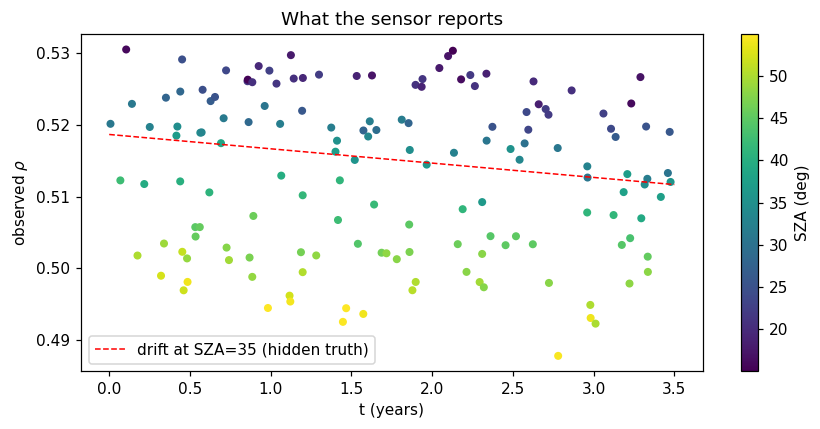

In [9]:
n = 150
t = np.sort(rng.uniform(0, 3.5, n))
sza = rng.uniform(15, 55, n)
cos_theta = np.cos(np.radians(sza))

R = a_true + b_true * t                    # Line 1
bracket = c_true + d_true * cos_theta      # geometry factor
rho_clean = bracket * R                    # Line 2: the composition
rho = rho_clean * (1 + 0.003 * rng.standard_normal(n))   # + 0.3% noise

fig, ax = plt.subplots(figsize=(8, 4))
sc = ax.scatter(t, rho, c=sza, cmap='viridis', s=18)
ax.plot(t_grid, (c_true + d_true*np.cos(np.radians(35))) * (a_true + b_true*t_grid),
        'r--', lw=1, label='drift at SZA=35 (hidden truth)')
plt.colorbar(sc, label='SZA (deg)')
ax.set_xlabel('t (years)'); ax.set_ylabel(r'observed $\rho$')
ax.set_title('What the sensor reports')
ax.legend()
plt.tight_layout(); plt.show()

This is the core problem in one picture. The drift (red dashed) is a ~1.3% decline over the record, but the geometry-driven scatter is ~3% peak to peak. Look at the color gradient: high points are yellow (low SZA), low points are purple (high SZA). The drift is buried under BRDF, and the point of the whole exercise is to dig it out.

## 3. Fit Line 3

Multiply out Line 2:

$$(c + d\cos\theta)(a + bt) = \underbrace{ca}_{\alpha} + \underbrace{cb}_{\beta}\,t + \underbrace{da}_{\gamma}\,\cos\theta + \underbrace{db}_{\eta}\,\cos\theta\, t$$

The product model is exactly linear in $(\alpha, \beta, \gamma, \eta)$, so ordinary linear least squares solves it in closed form. Build the design matrix — one column per parameter, one row per acquisition — and solve.

In [8]:
X = np.column_stack([
    np.ones(n),        # alpha  (intercept)
    t,                 # beta   (drift)
    cos_theta,         # gamma  (BRDF)
    cos_theta * t,     # eta    (interaction)
])

coef, _, _, _ = np.linalg.lstsq(X, rho, rcond=None)
alpha, beta, gamma, eta = coef

# standard errors from the fit covariance
residuals = rho - X @ coef
dof = n - X.shape[1]
cov = (residuals @ residuals / dof) * np.linalg.inv(X.T @ X)
se = np.sqrt(np.diag(cov))

true_vals = [c_true*a_true, c_true*b_true, d_true*a_true, d_true*b_true]
print(f"{'param':>6} {'fitted':>10} {'+/- SE':>9} {'true':>10}")
for name, f, s, tr in zip(['alpha','beta','gamma','eta'], coef, se, true_vals):
    print(f"{name:>6} {f:>10.5f} {s:>9.5f} {tr:>10.5f}")

 param     fitted    +/- SE       true
 alpha    0.44144   0.00169    0.44200
  beta   -0.00162   0.00086   -0.00170
 gamma    0.09471   0.00211    0.09360
   eta   -0.00071   0.00107   -0.00036


All four true values sit within roughly one standard error of the fits. Notice `beta` and `eta` have large *relative* uncertainties — that is real, not a bug. Over 15–55 degrees, $\cos\theta$ only spans ~0.57–0.97, so the column $\cos\theta \cdot t$ is nearly proportional to $t$ itself (correlation ~0.99). The two columns are almost collinear, and least squares struggles to split the drift between them. Keep this in mind: it is the statistical price of including the interaction term.

## 4. Recover the physical quantities

The ratios survive the expansion:

$$\frac{\beta}{\alpha} = \frac{cb}{ca} = \frac{b}{a}, \qquad \frac{\gamma}{\alpha} = \frac{da}{ca} = \frac{d}{c}$$

But because of the collinearity above, $\beta/\alpha$ alone is noisy. A better-determined quantity is the model's fractional drift evaluated at a fixed geometry $\bar{c}_\theta$ (e.g. the mean of the observed $\cos\theta$):

$$\text{drift}(\bar{c}_\theta) = \frac{\beta + \eta\,\bar{c}_\theta}{\alpha + \gamma\,\bar{c}_\theta}$$

For the true multiplicative model this equals $b/a$ at *any* geometry — check: $(cb + db\,\bar c_\theta)/(ca + da\,\bar c_\theta) = b(c + d\bar c_\theta)/[a(c + d\bar c_\theta)] = b/a$. Evaluating at the mean geometry uses the well-constrained parameter combinations instead of the poorly separated individual ones.

In [6]:
cbar = cos_theta.mean()

drift_naive_ratio = 100 * beta / alpha
drift_at_mean_geom = 100 * (beta + eta * cbar) / (alpha + gamma * cbar)

print(f"true fractional drift        : {100*b_true/a_true:+.3f} %/yr")
print(f"raw beta/alpha               : {drift_naive_ratio:+.3f} %/yr   (noisy: collinearity)")
print(f"drift at mean geometry       : {drift_at_mean_geom:+.3f} %/yr   (use this)")
print()
print(f"true d/c                     : {d_true/c_true:.4f}")
print(f"fitted gamma/alpha           : {gamma/alpha:.4f}")

true fractional drift        : -0.385 %/yr
raw beta/alpha               : -0.368 %/yr   (noisy: collinearity)
drift at mean geometry       : -0.424 %/yr   (use this)

true d/c                     : 0.2118
fitted gamma/alpha           : 0.2145


## 5. Why the *joint* fit matters: the conflation experiment

Now the payoff. Rerun the world, but make SZA **correlated with time** — the situation a sun-synchronous sensor with seasonal sampling gaps faces, and the failure mode a naive trend fit walks into. Here, SZA drifts systematically lower as the mission progresses, so the site appears to *brighten* from geometry even while the instrument dims.

In [6]:
t2 = np.sort(rng.uniform(0, 3.5, n))
sza2 = np.clip(50 - 8*t2 + rng.normal(0, 3, n), 10, 60)   # SZA falls over time
cth2 = np.cos(np.radians(sza2))
rho2 = (c_true + d_true*cth2) * (a_true + b_true*t2) * (1 + 0.003*rng.standard_normal(n))

print(f"corr(t, SZA) = {np.corrcoef(t2, sza2)[0,1]:+.2f}")

# Naive: trend rho against time, ignore geometry entirely
Xn = np.column_stack([np.ones(n), t2])
cn, _, _, _ = np.linalg.lstsq(Xn, rho2, rcond=None)

# Joint: full Line 3
Xj = np.column_stack([np.ones(n), t2, cth2, cth2*t2])
cj, _, _, _ = np.linalg.lstsq(Xj, rho2, rcond=None)
cbar2 = cth2.mean()

print(f"true drift                   : {100*b_true/a_true:+.3f} %/yr")
print(f"naive fit (ignore geometry)  : {100*cn[1]/cn[0]:+.3f} %/yr   <- wrong SIGN")
print(f"joint fit (at mean geometry) : {100*(cj[1]+cj[3]*cbar2)/(cj[0]+cj[2]*cbar2):+.3f} %/yr")

corr(t, SZA) = -0.93
true drift                   : -0.385 %/yr
naive fit (ignore geometry)  : +1.090 %/yr   <- wrong SIGN
joint fit (at mean geometry) : -0.460 %/yr


The naive fit doesn't just get the magnitude wrong — it reports the instrument *brightening*, because the geometry trend leaks into the time coefficient. The joint fit apportions the variance correctly and recovers a dimming close to truth (with wider error bars than the uncorrelated case — collinearity between $t$ and $\cos\theta$ costs statistical power, but not validity).

This is the quantitative version of: *sequential correct-then-trend lets BRDF errors contaminate the trend; joint fitting lets the two effects negotiate against the data simultaneously.*

## 6. $\theta$ vs $\cos\theta$ as the regressor

The boss suggested trying both. Fit Line 3 twice on the original (uncorrelated) data — once with $\cos\theta$, once with $\theta$ in degrees — and compare residuals.

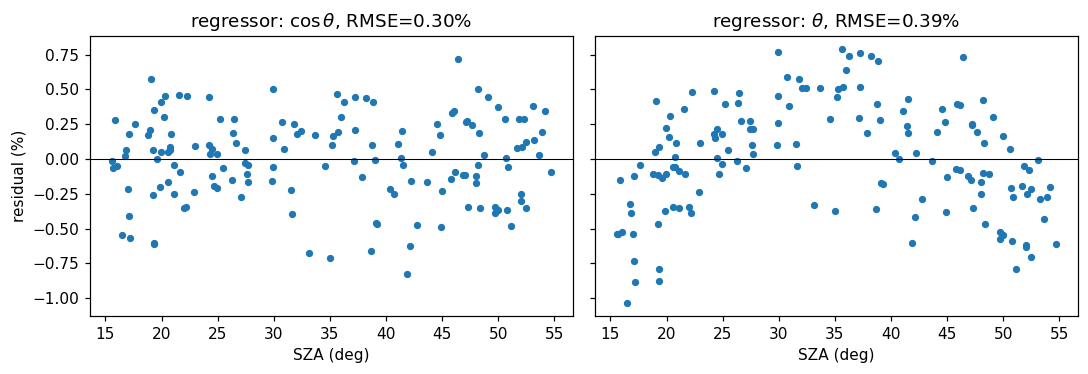

In [7]:
Xdeg = np.column_stack([np.ones(n), t, sza, sza*t])
cdeg, _, _, _ = np.linalg.lstsq(Xdeg, rho, rcond=None)

res_cos = rho - X @ coef
res_deg = rho - Xdeg @ cdeg

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, res, label in [(axes[0], res_cos, r'regressor: $\cos\theta$'),
                       (axes[1], res_deg, r'regressor: $\theta$')]:
    ax.scatter(sza, 100*res/rho, s=14)
    ax.axhline(0, color='k', lw=0.7)
    ax.set_xlabel('SZA (deg)'); ax.set_title(f'{label}, RMSE={100*np.sqrt(np.mean(res**2))/rho.mean():.2f}%')
axes[0].set_ylabel('residual (%)')
plt.tight_layout(); plt.show()

Because we *generated* the truth with $\cos\theta$, the cosine version fits slightly better and the $\theta$ version shows faint curvature in its residuals. On real data you don't know the truth — you make exactly this pair of plots and pick whichever residual panel looks more like structureless noise. If both look the same (likely over a 40-degree SZA range where $\cos\theta$ is nearly linear in $\theta$), the choice is inconsequential and the physically motivated cosine wins by default.

## 7. Identifiability: why individual parameters are scaffolding

Claim from our discussion: you can rescale $(c, d)$ up and $(a, b)$ down by the same factor and get *identical* predictions. Only the products — and therefore the ratios — are determined by data.

In [9]:
k = 2.0
rho_original = (c_true + d_true*cos_theta) * (a_true + b_true*t)
rho_rescaled = (k*c_true + k*d_true*cos_theta) * (a_true/k + b_true/k*t)

print(f"max |difference| = {np.abs(rho_original - rho_rescaled).max():.2e}")
print(f"b/a unchanged: {b_true/a_true:.5f} == {(b_true/k)/(a_true/k):.5f}")
print(f"d/c unchanged: {d_true/c_true:.5f} == {(k*d_true)/(k*c_true):.5f}")

max |difference| = 0.00e+00
b/a unchanged: -0.00385 == -0.00385
d/c unchanged: 0.21176 == 0.21176


Identical to machine precision. The data cannot tell you $c$; it can only tell you $ca$, $cb$, $da$, $db$ — which is exactly why Line 3 works with $(\alpha, \beta, \gamma, \eta)$ and why the reportable numbers are the scale-free ratios.

## 8. Connections to the real pipeline

- **Per channel, per site.** Everything above runs independently for each of the 285 channels at each of the 5 sites: 285 design matrices per site per product level (L1B and L2A in parallel).
- **Unit of analysis.** Here each row was one acquisition. In the pipeline, rows should be granule-level aggregates (or carry a granule random effect) — patch-level rows from the same granule are spatial replicates, and treating them as independent understates the uncertainty on the drift.
- **Weights.** The real fit is weighted least squares with 1/SE^2 weights (floored), replacing `lstsq` with its weighted equivalent.
- **Robustness.** If residual inspection shows outliers surviving QC masking, swap the closed-form solve for an L1 (or Huber) optimizer. Start with least squares; escalate only if the residuals demand it.
- **Diagnostics to keep.** The corr(t, SZA) check from Section 5 quantifies how much statistical power each site's sampling geometry gives you. The residual-vs-SZA plots from Section 6 settle the theta-vs-cosine question empirically.
- **eta's ambiguity.** In this framing eta = db is *required* by the multiplicative structure — it is drift modulated by geometry, not evidence of surface change. A fitted eta far from the value implied by beta*gamma/alpha would be the actual anomaly flag.